# 卷积（Convolution）

> 参考：维基百科（中文），「卷积」条目（2026-11-26 版本）。<https://zh.wikipedia.org/wiki/卷积>
>
> 本文是根据该条目整理的笔记加演示代码，不是原文的转载。原条目以外补充的内容另有标注。

## 定义

设 $f(t)$、$g(t)$ 是 $\mathbb R$ 上的两个可积函数，它们的卷积定义为

$$
(f*g)(t)\triangleq\int_{-\infty}^{\infty}f(\tau)\,g(t-\tau)\,d\tau
$$

结果仍是可积函数。换元 $\tau\to t-\tau$ 可知卷积满足交换律：

$$
(f*g)(t)=\int_{-\infty}^{\infty}f(t-\tau)\,g(\tau)\,d\tau=(g*f)(t)
$$

直观理解：把 $g$ **翻转**、**平移** $t$，与 $f$ 相乘，再求乘积曲线下的面积，结果就是 $t$ 处的卷积值。如果 $g$ 是某个区间上的指示函数（矩形，再除以区间长度），卷积就是"滑动平均"，所以卷积可以看作滑动平均的推广：换成别的 $g$，就是加权的滑动平均。

**只在 $[0,\infty)$ 上有值时**（因果信号），积分限可以截断：

$$
(f*g)(t)=\int_0^t f(\tau)\,g(t-\tau)\,d\tau,\qquad f,g:[0,\infty)\to\mathbb R
$$

积分限的来历：把 $f$、$g$ 在负半轴上补成 0，代回原定义 $\int_{-\infty}^{\infty}f(\tau)\,g(t-\tau)\,d\tau$，被积函数只在两个条件同时满足时才可能不为零：

- $f(\tau)\neq0$ 要求 $\tau\ge0$，所以下限是 $0$；
- $g(t-\tau)\neq0$ 要求 $t-\tau\ge0$，即 $\tau\le t$，所以上限是 $t$。
也就是说，$t$ 时刻的输出只由 $[0,t]$ 这段"过去"的输入决定，这正是"因果"的含义。$t<0$ 时区间 $[0,t]$ 为空，$(f*g)(t)=0$。单边拉普拉斯变换的卷积定理对应的就是这种卷积。

**多元函数**：

$$
(f*g)(\mathbf t)\triangleq\int_{\mathbb R^n}f(\boldsymbol\tau)\,g(\mathbf t-\boldsymbol\tau)\,d^n\boldsymbol\tau
$$

**工程记号的坑**：工程上常写 $f(t)*g(t)$，它的意思是 $(f*g)(t)$，不能直接把 $t$ 代进去理解。比如 $f(t)*g(t-t_0)=(f*g)(t-t_0)$，但 $f(t-t_0)*g(t-t_0)=(f*g)(t-2t_0)$：两个都平移 $t_0$，结果平移 $2t_0$。

### 历史

最早出现在达朗贝尔 1754 年对泰勒定理的推导中；拉克鲁瓦在 1797–1800 年的著作里使用了 $\int f(u)\,g(x-u)\,du$ 这类表达式；此后出现在拉普拉斯、傅里叶、泊松等人的工作中。这个运算曾被叫作 Faltung（德语"折叠"）、合成乘积、叠加积分、卡森积分。"卷积"一词 1903 年就已出现，但直到 1950–60 年代才通用。

### 存在性

若 $f,g\in L^1(\mathbb R^n)$（勒贝格可积），则卷积存在且 $f*g\in L^1$（托内利定理的推论）。更一般地，若 $f\in L^1$、$g\in L^p$（$1\le p\le\infty$），则 $f*g\in L^p$，并且有 Young 不等式的特例：

$$
\|f*g\|_p\le\|f\|_1\,\|g\|_p
$$

$p=1$ 时说明 $L^1$ 在卷积下构成巴拿赫代数；若 $f,g$ 几乎处处非负，等号成立。

### 平滑作用

$f*g$ 一般比 $f$ 和 $g$ 都光滑。特别地，若 $g$ 是紧支撑的光滑函数，$f$ 局部可积，则 $f*g$ 光滑。用这个性质可以构造一列光滑函数逼近任意可积函数，这叫**光滑化**（mollification / 正则化）。

In [14]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.integrate import quad

### 图解：翻转、平移、相乘、求面积

用矩形脉冲 $f$ 和指数衰减脉冲 $g$（RC 电路的冲激响应）演示：

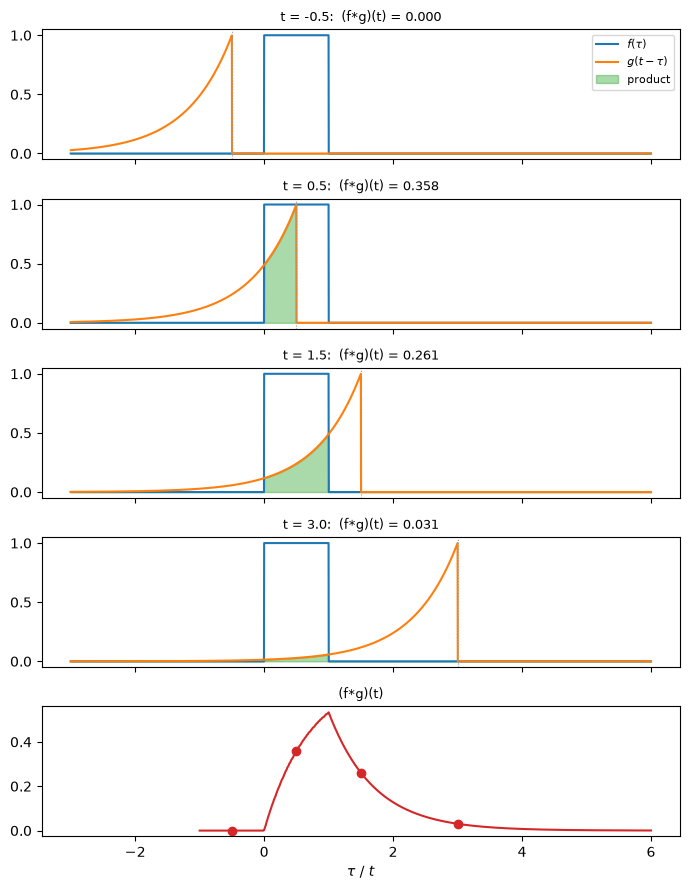

In [15]:
def f(t):
    return ((t >= 0) & (t <= 1)).astype(float)          # 矩形脉冲


def g(t):
    return np.where(t >= 0, np.exp(-t / 0.7), 0.0)      # 指数衰减脉冲


tau = np.linspace(-3, 6, 3001)
dtau = tau[1] - tau[0]
ts = [-0.5, 0.5, 1.5, 3.0]

fig, axes = plt.subplots(len(ts) + 1, 1, figsize=(7, 9), sharex=True)
for ax, t in zip(axes, ts):
    prod = f(tau) * g(t - tau)
    ax.plot(tau, f(tau), label=r"$f(\tau)$")
    ax.plot(tau, g(t - tau), label=r"$g(t-\tau)$")
    ax.fill_between(tau, prod, color="C2", alpha=0.4, label="product")
    ax.set_title(f"t = {t}:  (f*g)(t) = {prod.sum() * dtau:.3f}", fontsize=9)
    ax.axvline(t, color="0.6", ls=":", lw=0.8)
axes[0].legend(fontsize=8, loc="upper right")

# 让 t 连续变化，得到完整的卷积曲线
t_grid = np.linspace(-1, 6, 701)
conv = np.array([np.sum(f(tau) * g(t - tau)) * dtau for t in t_grid])
axes[-1].plot(t_grid, conv, color="C3")
axes[-1].plot(ts, [np.sum(f(tau) * g(t - tau)) * dtau for t in ts], "o", color="C3")
axes[-1].set_title("(f*g)(t)", fontsize=9)
axes[-1].set_xlabel(r"$\tau$ / $t$")
plt.tight_layout()
plt.show()

## 与卷积相关的几个运算

**互相关**（cross-correlation）：

$$
(f\star g)(\tau)\triangleq\int_{-\infty}^{\infty}\overline{f(t-\tau)}\,g(t)\,dt=\overline{f(-\tau)}*g(\tau)
$$

$\tau$ 叫作位移（displacement）或滞后（lag）。和卷积的区别在于 $f$ 不翻转（并取共轭）。$f$ 是关于 0 对称的实函数（偶函数）时，$f\star g=f*g$。

**冲激响应**：单位冲激 $\delta(t)$ 是卷积的单位元，$(\delta*h)(t)=h(t)$。在线性时不变（LTI）系统中，输出等于输入与冲激响应的卷积：

$$
y(t)=(x*h)(t)=\int_{-\infty}^{\infty}x(\tau)\,h(t-\tau)\,d\tau
$$

**独立随机变量之和**：若 $U$、$V$ 独立，则 $U+V$ 的概率密度是各自密度的卷积：

$$
f_{U+V}(x)=\int_{-\infty}^{\infty}f_U(y)\,f_V(x-y)\,dy=(f_U*f_V)(x)
$$

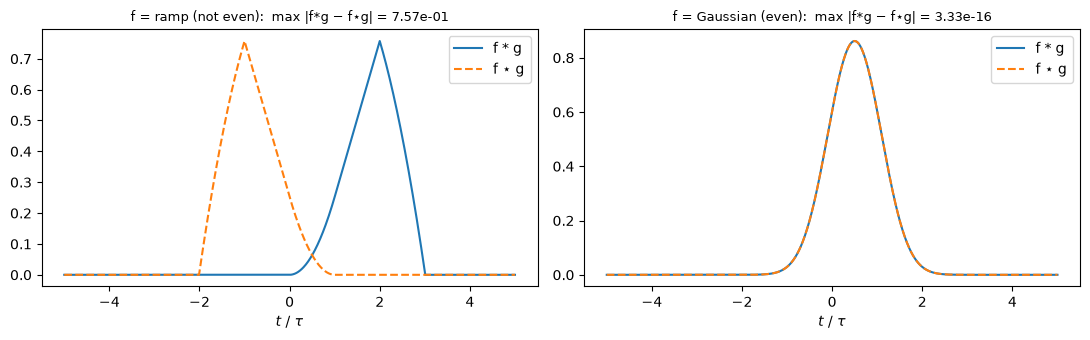

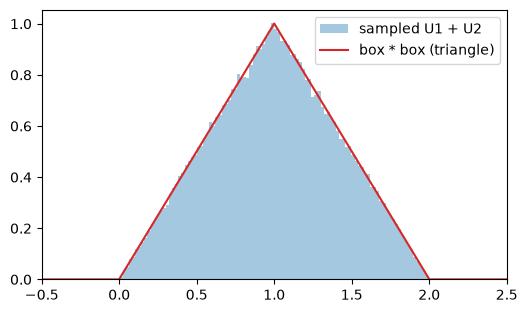

In [16]:
# 卷积 vs 互相关：f 不是偶函数时两者不同，f 是偶函数时相同
x = np.linspace(-5, 5, 1001)                           # 奇数个点、关于 0 对称
dx = x[1] - x[0]
ramp = np.where((x >= 0) & (x <= 2), x / 2, 0.0)       # 不对称的斜坡（不是偶函数）
even = np.exp(-x**2 / 0.5)                             # 偶函数
g = np.where((x >= 0) & (x <= 1), 1.0, 0.0)            # 矩形

# scipy 的 correlate(in1, in2) 计算 Σ in1[n+k]·conj(in2[n])，对应本文记号的 in2 ⋆ in1
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, (name, f_) in zip(axes, [("ramp (not even)", ramp), ("Gaussian (even)", even)]):
    conv = signal.convolve(f_, g, mode="same") * dx
    corr = signal.correlate(g, f_, mode="same") * dx     # = f ⋆ g
    ax.plot(x, conv, label="f * g")
    ax.plot(x, corr, "--", label=r"f $\star$ g")
    ax.set_title(f"f = {name}:  max |f*g − f⋆g| = {np.abs(conv - corr).max():.2e}", fontsize=9)
    ax.set_xlabel(r"$t$ / $\tau$")
    ax.legend()
plt.tight_layout()
plt.show()

# 独立随机变量之和：两个 U(0,1) 之和是三角分布
rng = np.random.default_rng(0)
s = rng.uniform(size=200_000) + rng.uniform(size=200_000)
u = np.linspace(-1, 3, 4001)
du = u[1] - u[0]
box = ((u >= 0) & (u <= 1)).astype(float)
pdf = np.convolve(box, box, mode="full") * du
u_full = np.arange(pdf.size) * du + 2 * u[0]

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.hist(s, bins=100, density=True, alpha=0.4, label="sampled U1 + U2")
ax.plot(u_full, pdf, color="C3", label="box * box (triangle)")
ax.set_xlim(-0.5, 2.5)
ax.legend()
plt.show()

注意 `np.convolve(..., mode="full")` 的输出长度是 $N+M-1$，起点是两个输入起点之和，所以要重新构造横坐标，否则曲线会错位。

## 性质

### 代数性质

| 性质 | 公式 |
|---|---|
| 交换律 | $f*g=g*f$ |
| 结合律 | $f*(g*h)=(f*g)*h$ |
| 分配律 | $f*(g+h)=f*g+f*h$ |
| 数乘结合律 | $a(f*g)=(af)*g=f*(ag)$，$a$ 为实数或复数 |
| 复共轭 | $\overline{f*g}=\bar f*\bar g$ |
| 单位元 | $\delta*f=f$ |

### 积分

若 $F(t)=\int_{-\infty}^t f(\tau)\,d\tau$，$G(t)=\int_{-\infty}^t g(\tau)\,d\tau$，则

$$
(F*g)(t)=(f*G)(t)=\int_{-\infty}^t(f*g)(\tau)\,d\tau
$$

整个空间上，卷积的积分等于积分的乘积（富比尼定理；非负可测函数用托内利定理）：

$$
\int_{\mathbb R^n}(f*g)(\mathbf t)\,d^n\mathbf t=\left(\int_{\mathbb R^n}f\right)\left(\int_{\mathbb R^n}g\right)
$$

这条在谱学里很有用：用面积归一化的仪器函数去卷积，**峰面积不变**。

### 微分

$$
\frac{d}{dt}(f*g)=\frac{df}{dt}*g=f*\frac{dg}{dt},\qquad
\frac{\partial}{\partial t_i}(f*g)=\frac{\partial f}{\partial t_i}*g=f*\frac{\partial g}{\partial t_i}
$$

所以卷积是一种"光滑"运算：$f*g$ 的可微次数（至少）是 $f$ 和 $g$ 可微次数之和。严格成立的条件是 $f,g$ 绝对可积，且至少一个有 $L^1$ 的弱导数（Young 卷积不等式的推论）。离散情形下，差分算子 $\Delta f(n)=f(n+1)-f(n)$ 有同样的关系：$\Delta(f*g)=(\Delta f)*g=f*(\Delta g)$。

In [17]:
# 用离散卷积数值验证上面的性质
x = np.linspace(-10, 10, 2001)
dx = x[1] - x[0]
conv = lambda p, q: signal.convolve(p, q, mode="same") * dx

f1 = np.exp(-x**2)
g1 = 1 / (1 + x**2)
h1 = np.where(np.abs(x) < 1, 1.0, 0.0)
mid = np.abs(x) < 4                        # 只在中间比较，避开截断边缘的影响

print("交换律   :", np.abs(conv(f1, g1) - conv(g1, f1))[mid].max())
print("结合律   :", np.abs(conv(f1, conv(g1, h1)) - conv(conv(f1, g1), h1))[mid].max())
print("分配律   :", np.abs(conv(f1, g1 + h1) - (conv(f1, g1) + conv(f1, h1)))[mid].max())
print("微分     :", np.abs(np.gradient(conv(f1, g1), x) - conv(np.gradient(f1, x), g1))[mid].max())

# 积分的乘积（用 full 模式，不丢掉两端）
full = signal.convolve(f1, g1, mode="full") * dx
print(f"∫(f*g) = {full.sum() * dx:.4f}   (∫f)(∫g) = {f1.sum() * dx * g1.sum() * dx:.4f}")

交换律   : 8.881784197001252e-16
结合律   : 8.881784197001252e-16
分配律   : 1.3322676295501878e-15
微分     : 5.573319583618286e-14
∫(f*g) = 5.2152   (∫f)(∫g) = 5.2152


## 卷积定理

设 $G(s)$、$H(s)$ 分别是 $g$、$h$ 的傅里叶变换（约定 $\mathcal F\{g\}(s)=\int g(x)e^{-i2\pi sx}dx$），则

$$
\mathcal F\{g*h\}=G\cdot H,\qquad \mathcal F\{g\cdot h\}=G*H
$$

即：**一个域里的卷积等于另一个域里的逐点乘积**。取逆变换得

$$
g*h=\mathcal F^{-1}\{G\cdot H\},\qquad g\cdot h=\mathcal F^{-1}\{G*H\}
$$

原条目说这个定理对拉普拉斯变换、双边拉普拉斯变换、Z 变换、梅林变换、Hartley 变换"同样成立"，在调和分析里还可以推广到局部紧致阿贝尔群上的傅里叶变换。这句话需要补充说明，因为各个变换对应的"卷积"和"乘积"并不完全一样：

- **双边拉普拉斯变换**：和傅里叶变换一样，对应普通卷积；
- **（单边）拉普拉斯变换**：对应因果卷积 $\int_0^t f(\tau)g(t-\tau)\,d\tau$；
- **Z 变换**：对应离散卷积；
- **梅林变换**：对应的是梅林卷积（乘法卷积）$\int_0^\infty f(x/y)\,g(y)\,\frac{dy}{y}$，不是普通卷积；
- **Hartley 变换**：卷积的变换**不是**简单的逐点乘积，而是 $\mathcal H\{f*g\}(\omega)=\tfrac12\left[F(\omega)\big(G(\omega)+G(-\omega)\big)+F(-\omega)\big(G(\omega)-G(-\omega)\big)\right]$（$F$、$G$ 为 Hartley 变换）。
之前笔记里的几个结论都是它的直接推论（这里用本节的约定 $e^{-i2\pi sx}$）：

- 高斯 * 高斯 = 高斯：标准差为 $\sigma$ 的归一化高斯，傅里叶变换为 $e^{-2\pi^2\sigma^2s^2}$，相乘后指数相加，所以 $\sigma^2$ 相加。
- 洛伦兹 * 洛伦兹 = 洛伦兹：HWHM 为 $\gamma$ 的归一化洛伦兹，傅里叶变换为 $e^{-2\pi\gamma|s|}$，所以 $\gamma$ 相加（补充）。
- Voigt 的傅里叶变换 $e^{-2\pi\gamma|s|-2\pi^2\sigma^2s^2}$ 就是两者的乘积（Voigt 笔记里用的是特征函数的约定 $e^{ixt}$，写成 $e^{-\gamma|t|-\sigma^2t^2/2}$，两者只差变量替换 $t=2\pi s$）。

In [18]:
# 1) 卷积定理本身：补零后，"FFT → 相乘 → 逆 FFT" 与直接卷积完全一致
rng = np.random.default_rng(0)
a, b = rng.normal(size=300), rng.normal(size=120)
P = a.size + b.size - 1
via_fft = np.fft.ifft(np.fft.fft(a, n=P) * np.fft.fft(b, n=P)).real
print("直接卷积 vs FFT 相乘:", np.abs(np.convolve(a, b) - via_fft).max())

# 2) 推论：洛伦兹 * 洛伦兹 = 洛伦兹，γ 相加
lor = lambda x, g: g / (np.pi * (x**2 + g**2))
g1, g2 = 0.5, 1.2
dx = 0.01
for half_width in (200, 2000):
    n = int(half_width / dx)
    x = np.arange(-n, n + 1) * dx          # 奇数个点、关于 0 对称：mode="same" 才不会错开半个格点
    conv = signal.fftconvolve(lor(x, g1), lor(x, g2), mode="same") * dx
    mid = np.abs(x) < 10
    print(f"区间 ±{half_width}: 与洛伦兹(γ1+γ2)的最大偏差 {np.abs(conv - lor(x, g1 + g2))[mid].max():.1e}")
# 剩下的微小偏差来自把洛伦兹尾部截断在有限区间内，区间越宽越小
# 注意：如果网格点数是偶数，mode="same" 的结果会错开一个格点，这个例子里偏差会变成 7e-4，大好几个数量级

直接卷积 vs FFT 相乘: 2.842170943040401e-14
区间 ±200: 与洛伦兹(γ1+γ2)的最大偏差 5.5e-09
区间 ±2000: 与洛伦兹(γ1+γ2)的最大偏差 5.1e-12


### 周期函数与傅里叶级数

对周期为 $P$ 的 $g_P$、$h_P$，傅里叶级数系数 $G[k]=\frac1P\int_P g_P(x)e^{-i2\pi kx/P}dx$。逐点乘积的系数是系数的离散卷积：$\mathcal F\{g_P\cdot h_P\}[k]=(G*H)[k]$；周期卷积的系数是系数之积（多一个因子 $P$）：$\mathcal F\{g_P*h\}[k]=P\cdot G[k]\,H[k]$。

### 离散情形

序列 $g[n]$、$h[n]$ 的离散时间傅里叶变换（DTFT）$G(s)=\sum_n g[n]e^{-i2\pi sn}$，同样有 $\mathcal F\{g*h\}=G\cdot H$。

对长度为 $N$ 的离散傅里叶变换（DFT）：

$$
(g_N*h)[n]=\mathcal F^{-1}\{\mathcal F\{g_N\}\cdot\mathcal F\{h_N\}\}
$$

**关键点**：DFT 对应的是**圆周卷积**，不是普通的线性卷积。要用 FFT 算出线性卷积，必须先补零到长度 $P\ge M+N-1$，否则尾部会"绕回"开头叠加上去（混叠）。

In [19]:
a = np.array([1, 2, 3, 4, 5], dtype=float)
b = np.array([1, 1, 1], dtype=float)

linear = np.convolve(a, b)                                     # 长度 N+M-1 = 7
circular_N = np.fft.ifft(np.fft.fft(a) * np.fft.fft(b, n=a.size)).real   # 不补零：长度 5，圆周卷积
P = a.size + b.size - 1
padded = np.fft.ifft(np.fft.fft(a, n=P) * np.fft.fft(b, n=P)).real      # 补零到 P

print("线性卷积       :", linear)
print("FFT 不补零(圆周):", np.round(circular_N, 10))
print("FFT 补零到 P   :", np.round(padded, 10))

线性卷积       : [ 1.  3.  6.  9. 12.  9.  5.]
FFT 不补零(圆周): [10.  8.  6.  9. 12.]
FFT 补零到 P   : [ 1.  3.  6.  9. 12.  9.  5.]


## 离散卷积

定义在整数上的序列 $f[n]$、$g[n]$：

$$
(f*g)[n]\triangleq\sum_{m=-\infty}^{\infty}f[m]\,g[n-m]=\sum_{m=-\infty}^{\infty}f[n-m]\,g[m]
$$

定义域以外的值当作 0。若 $g$ 只在 $\{-M,\dots,M\}$ 上非零，就变成有限求和 $\sum_{m=-M}^{M}f[n-m]\,g[m]$。

**多项式乘法就是系数的卷积**（这叫序列的柯西乘积）；整数乘法也是（按位卷积后再进位）。

**多维离散卷积**：$M$ 维信号写作 $y=h *^{M}\cdots* x$，即

$$
y(n_1,\dots,n_M)=\sum_{k_1}\cdots\sum_{k_M}h(k_1,\dots,k_M)\,x(n_1-k_1,\dots,n_M-k_M)
$$

In [20]:
# 多项式乘法 = 系数卷积：(1 + 2x + 3x²)(4 + 5x)
p = [1, 2, 3]
q = [4, 5]
print("卷积        :", np.convolve(p, q))                    # 升幂系数
print("多项式乘法   :", np.polynomial.polynomial.polymul(p, q))

# 整数乘法：123 × 45，逐位卷积后再处理进位
digits = np.convolve([3, 2, 1], [5, 4])                      # 个位在前
print("逐位卷积     :", digits, " → ", sum(int(d) * 10**i for i, d in enumerate(digits)), "=", 123 * 45)

卷积        : [ 4 13 22 15]
多项式乘法   : [ 4. 13. 22. 15.]
逐位卷积     : [15 22 13  4]  →  5535 = 5535


### 离散周期卷积与圆周卷积

周期为 $N$ 的周期求和 $x_N[n]=\sum_k x[n-kN]$，周期卷积为 $(h*x_N)[n]=\sum_m h[m]\,x_N[n-m]$。若 $h$、$x$ 只在 $[0,N-1]$ 上非零，就是**圆周卷积**：

$$
(h*x_N)[n]=\sum_{m=0}^{N-1}h[m]\,x[(n-m)\bmod N]
$$

圆周卷积可以写成**循环矩阵**乘以向量：

$$
\begin{bmatrix}y_0\\y_1\\\vdots\\y_{N-1}\end{bmatrix}=
\begin{bmatrix}h_0&h_{N-1}&\cdots&h_1\\h_1&h_0&\cdots&h_2\\\vdots&\vdots&\ddots&\vdots\\h_{N-1}&h_{N-2}&\cdots&h_0\end{bmatrix}
\begin{bmatrix}x_0\\x_1\\\vdots\\x_{N-1}\end{bmatrix}
$$

FFT 的一些实现（比如 Rader 算法）里就会用到圆周卷积。


In [21]:
from scipy.linalg import circulant

h = np.array([1.0, 2, 3, 0, 0])
x = np.array([1.0, 0, 2, 1, 4])
N = x.size

y_def = np.array([sum(h[m] * x[(n - m) % N] for m in range(N)) for n in range(N)])
y_mat = circulant(h) @ x
y_fft = np.fft.ifft(np.fft.fft(h) * np.fft.fft(x)).real
print("按定义   :", y_def)
print("循环矩阵 :", y_mat)
print("FFT      :", np.round(y_fft, 10))

按定义   : [12. 14.  5.  5. 12.]
循环矩阵 : [12. 14.  5.  5. 12.]
FFT      : [12. 14.  5.  5. 12.]


## 离散卷积的计算方法

设 $f$ 长度 $N$，$g$ 长度 $M$。三种主要方法：

| 方法 | 做法 | 复杂度 |
|---|---|---|
| 1. 直接计算 | 按定义求和；实数信号需要 $MN$ 次乘法 | $O(MN)$ |
| 2. 快速傅里叶变换（FFT） | 两次 $P$ 点 DFT、相乘、一次 IDFT，$P\ge M+N-1$ | $O(P\log P)$ |
| 3. 分段卷积（sectioned） | 把长序列切成长度 $L$ 的段，每段用 FFT 和短序列卷积再拼起来 | 与 $N$ 成线性 |

分段卷积有两种拼法：

**Overlap-Add（重叠相加）**：把 $x$ 每 $L$ 点切一段；每段补 $M-1$ 个零，$h$ 补 $L-1$ 个零，都变成长度 $L+M-1$；每段做快速卷积得到长度 $L+M-1$ 的结果；第 $i$ 段放在 $L\cdot i$ 处，相邻段尾部的 $M-1$ 点重叠，**相加**。

**Overlap-Save（重叠保留）**：$x$ 前面补 $M-1$ 个零；每段取 $L$ 点，相邻段重复前一段的 $M-1$ 点；$h$ 补零到长度 $L$；每段做 $L$ 点圆周卷积，**丢掉**前 $M-1$ 点（这些点被圆周卷积的绕回污染了），只**保留**后 $L-(M-1)$ 点，依次拼起来。

In [22]:
def overlap_add(x, h, L):
    M = h.size
    P = L + M - 1
    H = np.fft.fft(h, n=P)
    y = np.zeros(x.size + M - 1)
    for start in range(0, x.size, L):
        seg = x[start:start + L]
        yseg = np.fft.ifft(np.fft.fft(seg, n=P) * H).real
        end = min(start + P, y.size)
        y[start:end] += yseg[:end - start]
    return y


def overlap_save(x, h, L):
    M = h.size
    step = L - (M - 1)
    H = np.fft.fft(h, n=L)
    xp = np.concatenate([np.zeros(M - 1), x, np.zeros(L)])   # 前面补 M-1 个零，后面补零方便取最后一段
    out = []
    for start in range(0, x.size + M - 1, step):
        seg = xp[start:start + L]
        yseg = np.fft.ifft(np.fft.fft(seg) * H).real
        out.append(yseg[M - 1:])                             # 丢掉前 M-1 点
    return np.concatenate(out)[:x.size + M - 1]


# 原条目中的两个例子
x1 = np.array([1, 2, 3, 4, 5, -1, -2, -3, -4, -5, 1, 2, 3, 4, 5], dtype=float)
x2 = np.arange(1, 16, dtype=float)
h = np.array([1.0, 2, 3])

print("Overlap-Add  (L=5):", np.round(overlap_add(x1, h, 5), 10))
print("直接卷积          :", np.convolve(x1, h))
print("Overlap-Save (L=7):", np.round(overlap_save(x2, h, 7), 10))
print("直接卷积          :", np.convolve(x2, h))
print("scipy.signal.oaconvolve 与直接卷积一致:", np.allclose(signal.oaconvolve(x1, h), np.convolve(x1, h)))

Overlap-Add  (L=5): [  1.   4.  10.  16.  22.  21.  11. -10. -16. -22. -21. -11.  10.  16.
  22.  22.  15.]
直接卷积          : [  1.   4.  10.  16.  22.  21.  11. -10. -16. -22. -21. -11.  10.  16.
  22.  22.  15.]
Overlap-Save (L=7): [ 1.  4. 10. 16. 22. 28. 34. 40. 46. 52. 58. 64. 70. 76. 82. 72. 45.]
直接卷积          : [ 1.  4. 10. 16. 22. 28. 34. 40. 46. 52. 58. 64. 70. 76. 82. 72. 45.]
scipy.signal.oaconvolve 与直接卷积一致: True


### 选哪种方法

原条目按长度给出了粗略的建议：

| 情况 | 推荐 |
|---|---|
| $M$ 很小 | 直接计算 |
| $M\ll N$ | 分段卷积 |
| $M\approx N$ | FFT |
| $M\gg N$ | 分段卷积 |
| $N$ 很小 | 直接计算 |

条目里还逐一算了总乘法量的例子（按复数信号计，直接法 $3MN$ 次）：$N=2000,M=17$ 时分段卷积（约 2.1 万次）优于 FFT（约 4.4 万次）和直接计算（约 10 万次）；$N=1024,M=3$ 时分段卷积（5476 次）也略优于直接计算（9216 次）；$N=1024,M=600$ 时最优是只切一段，分段卷积就退化成 FFT。实际使用时，最好是把三种方法的乘法量都算出来再选。（原条目第三个例子的方法 2 里写着"選擇 1026 點 DFT 附近"，按上下文应为 1623 点，是笔误，不影响结论。）

在 Python 里不用自己选：`scipy.signal.convolve(..., method="auto")` 会估算直接法和 FFT 哪个快并自动选择，`scipy.signal.choose_conv_method` 可以查看它选了哪个；`scipy.signal.oaconvolve` 就是 overlap-add 的实现。

In [23]:
import time

rng = np.random.default_rng(1)
for N, M in [(2000, 17), (1024, 3), (1024, 600), (200_000, 51), (100_000, 100_000)]:
    a, b = rng.normal(size=N), rng.normal(size=M)
    times = {}
    for name, fn in [("direct", lambda: signal.convolve(a, b, method="direct")),
                     ("fft", lambda: signal.fftconvolve(a, b)),
                     ("overlap-add", lambda: signal.oaconvolve(a, b))]:
        if name == "direct" and N * M > 2e9:
            times[name] = float("nan")                      # 太慢，跳过
            continue
        t0 = time.perf_counter()
        for _ in range(3):
            fn()
        times[name] = (time.perf_counter() - t0) / 3 * 1e3
    auto = signal.choose_conv_method(a, b)
    print(f"N={N:>7}, M={M:>7}:  " + "  ".join(f"{k} {v:8.3f} ms" for k, v in times.items())
          + f"   auto→{auto}")

N=   2000, M=     17:  direct    0.040 ms  fft    0.172 ms  overlap-add    0.346 ms   auto→direct
N=   1024, M=      3:  direct    0.010 ms  fft    0.152 ms  overlap-add    0.233 ms   auto→direct
N=   1024, M=    600:  direct    0.089 ms  fft    0.348 ms  overlap-add    0.081 ms   auto→direct
N= 200000, M=     51:  direct    2.912 ms  fft   10.621 ms  overlap-add    4.799 ms   auto→direct
N= 100000, M= 100000:  direct      nan ms  fft   10.800 ms  overlap-add   10.232 ms   auto→fft


我在自己机器上跑的结果（具体数值因机器而异）：

- 原条目按乘法次数分析，认为 $N=2000,M=17$ 和 $N=1024,M=600$ 时应该用分段卷积或 FFT；但实测在这类规模下，**直接法反而最快**，`auto` 也选了直接法。原因是现代 CPU 的向量化让直接法的乘法很便宜，而 FFT 有额外开销（补零、复数运算、内存分配），乘法次数只是计算量的一部分。
- 长信号配短核（$N=200000,M=51$）时，overlap-add 和直接法相当，都比整段 FFT 快；
- 两个都很长（$N=M=10^5$）时，直接法要算 $10^{10}$ 次乘法，FFT 和 overlap-add 只要几毫秒。
所以原条目"算出乘法量再选方法"的思路在大规模问题上是对的；但对谱数据这种几千个点的规模，直接用 `scipy.signal.convolve` 让它自动选就行。

## 推广

卷积可以推广到数列、测度和广义函数（分布）上。不定义在 $\mathbb R^n$ 上的函数，可以把定义域以外的值规定为 0，变成 $\mathbb R^n$ 上的函数。

对定义在群 $G$ 上（有测度 $m$，例如局部紧致拓扑群上的哈尔测度）的可积函数，原条目给出的定义是

$$
(f*g)(x)=\int_G f(y)\,g(xy^{-1})\,dm(y)
$$

注意：使用左哈尔测度时，更常见的写法是 $\int_G f(y)\,g(y^{-1}x)\,dm(y)$；对阿贝尔群（比如 $\mathbb R^n$、$\mathbb Z$）两种写法相同，都退化为普通卷积。这时的卷积定理等性质要用到群表示论和调和分析，对紧群用的是彼得–外尔定理。

## 应用

原条目列出的应用：

- 代数：整数乘法、多项式乘法；
- 卷积神经网络（CNN）：多重级联的卷积核，用于机器视觉和人工智能（不过大多数实现实际算的是互相关）；
- 图像处理：模糊、锐化、边缘检测；
- 统计学：加权滑动平均；
- 概率论：独立随机变量之和的概率密度；
- 声学：回声 = 源声 * 反射响应；
- 信号处理：线性系统的输出 = 输入 * 冲激响应；
- 物理学：任何满足叠加原理的线性系统。
### 补充：谱学中的卷积

**仪器展宽**：测到的谱 = 真实谱 * 仪器函数（再加噪声）。XPS、Raman、XRD 里看到的峰都被仪器的分辨率展宽过。Voigt 线形的一个常见来源就是本征的洛伦兹线形与高斯型展宽的卷积，这里的高斯展宽既可以来自仪器，也可以来自样品的非均匀性。仪器函数面积归一化时，峰面积不变。（实际的仪器函数不一定是高斯形，比如 XRD 的仪器峰形通常不对称。）

**平滑**：滑动平均、高斯平滑、Savitzky–Golay 滤波都是和一个固定的核做卷积。核越宽，噪声越小，但峰也会被展宽、变矮，所以平滑之后再测 FWHM 会偏大。

**反卷积**：想从测量谱中"去掉"仪器展宽，原理上是在频域相除：$F=Y/H$。但高频处 $H$ 很小，噪声会被极度放大，所以实际要用正则化的方法（如 Wiener 滤波、Richardson–Lucy 迭代），或者干脆在拟合时把仪器函数作为卷积的一部分（正向建模），后者更稳妥。

真实谱面积 1.5795，展宽后面积 1.5792（仅受截断影响）


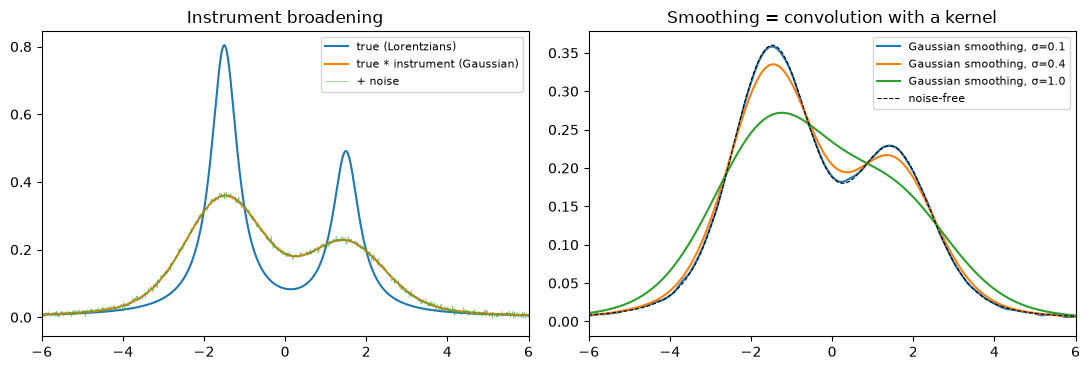

In [24]:
# 示例：两个洛伦兹峰经过高斯仪器函数展宽，再加噪声，然后做不同宽度的平滑
x = np.linspace(-20, 20, 4001)
dx = x[1] - x[0]
lor = lambda x, x0, g: g / (np.pi * ((x - x0) ** 2 + g**2))
gauss = lambda x, s: np.exp(-x**2 / (2 * s**2)) / (s * np.sqrt(2 * np.pi))

true = lor(x, -1.5, 0.4) + 0.6 * lor(x, 1.5, 0.4)
measured = signal.convolve(true, gauss(x, 0.8), mode="same") * dx         # 仪器展宽
rng = np.random.default_rng(3)
noisy = measured + rng.normal(0, 0.005, x.size)

print(f"真实谱面积 {true.sum() * dx:.4f}，展宽后面积 {measured.sum() * dx:.4f}（仅受截断影响）")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(x, true, label="true (Lorentzians)")
axes[0].plot(x, measured, label="true * instrument (Gaussian)")
axes[0].plot(x, noisy, lw=0.5, alpha=0.6, label="+ noise")
axes[0].set_xlim(-6, 6)
axes[0].legend(fontsize=8)
axes[0].set_title("Instrument broadening")

for s in (0.1, 0.4, 1.0):
    half = int(round(5 * s / dx))
    k = gauss(np.arange(-half, half + 1) * dx, s) * dx                      # 奇数长度、对称的离散高斯核
    axes[1].plot(x, signal.convolve(noisy, k, mode="same"), label=f"Gaussian smoothing, σ={s}")
axes[1].plot(x, measured, "k--", lw=0.8, label="noise-free")
axes[1].set_xlim(-6, 6)
axes[1].legend(fontsize=8)
axes[1].set_title("Smoothing = convolution with a kernel")
plt.tight_layout()
plt.show()

### 补充：二维卷积（图像处理）

SEM 图像的降噪、锐化、边缘检测都是二维卷积。下面用一个模拟的颗粒图像演示：

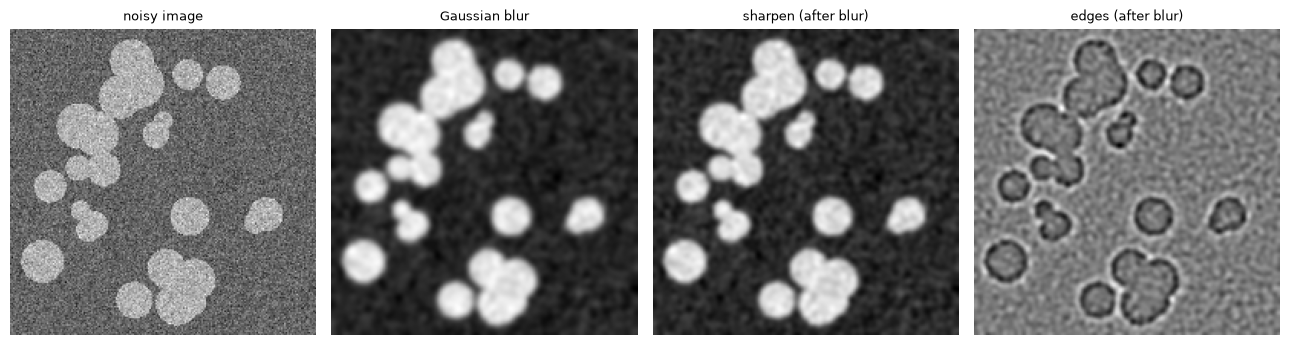

In [25]:
from scipy import ndimage

rng = np.random.default_rng(7)
img = np.zeros((200, 200))
yy, xx = np.mgrid[:200, :200]
for cx, cy, r in rng.uniform([20, 20, 6], [180, 180, 16], size=(25, 3)):
    img[(xx - cx) ** 2 + (yy - cy) ** 2 < r**2] = 1.0
img = img + rng.normal(0, 0.3, img.shape)

sharpen = np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]])
laplacian = np.array([[0, 1, 0], [1, -4, 1], [0, 1, 0]])
blurred = ndimage.gaussian_filter(img, 2)               # 高斯模糊：与二维高斯核卷积
results = {
    "noisy image": img,
    "Gaussian blur": blurred,
    "sharpen (after blur)": signal.convolve2d(blurred, sharpen, mode="same", boundary="symm"),
    "edges (after blur)": signal.convolve2d(blurred, laplacian, mode="same", boundary="symm"),
}
fig, axes = plt.subplots(1, 4, figsize=(13, 3.5))
for ax, (name, im) in zip(axes, results.items()):
    ax.imshow(im, cmap="gray")
    ax.set_title(name, fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 相关条目

- 反卷积（Deconvolution）
- 自相关函数（Autocorrelation）
- 傅里叶变换（Fourier transform）
- 同系列笔记：[Lorentzian Function](lorentzian-function.md)、[Gaussian Function](gaussian-function.md)、[Voigt Profile](voigt-profile.md)